## 1. Данные и подключение к Ollama

In [1]:
from pathlib import Path
from collections import Counter
from time import perf_counter
from typing import Literal
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset
from pydantic import BaseModel, ConfigDict
from ollama import Client

DATA = Path("data")
DATA.mkdir(exist_ok=True)
client = Client(host="http://ollama:11434", timeout=300)
dataset = load_dataset("tner/conll2003", split="train")
sample_ids = np.random.default_rng(42).choice(len(dataset), size=100, replace=False)
sample = dataset.select(sample_ids.tolist())
print("Предложений:", len(sample))
print(dataset.features)
print(sample[0])


Предложений: 100
{'tokens': Sequence(feature=Value(dtype='string', id=None), length=-1, id=None), 'tags': Sequence(feature=Value(dtype='int32', id=None), length=-1, id=None)}
{'tokens': ['The', 'other', 'was', 'insurer', 'Thierry', 'Dehaan', '.'], 'tags': [0, 0, 0, 0, 3, 4, 0]}


## 2. BIO-разметка и разведочный анализ

split,development,evaluation
type,,
LOC,10,50
MISC,6,18
ORG,13,29
PER,10,37


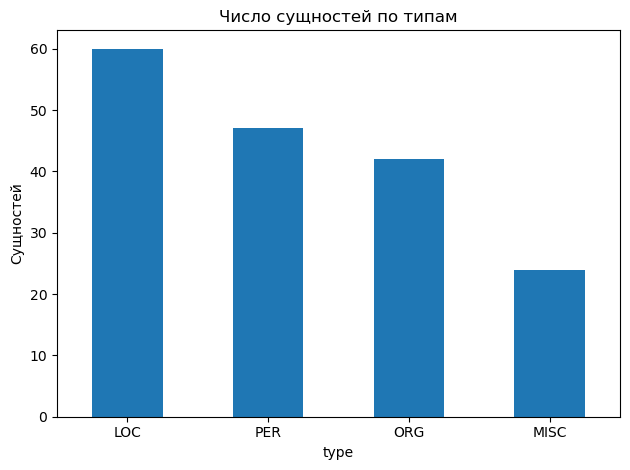

,id,split,text
0,6130,development,The other was insurer Thierry Dehaan .
1,13184,development,But European grain traders and officials said ...
2,9391,development,PARIS 1996-08-27


[{'text': 'Thierry Dehaan', 'type': 'PER', 'start': 4, 'end': 6}]


In [2]:
id_to_tag = {0: "O", 1: "B-ORG", 2: "B-MISC", 3: "B-PER", 4: "I-PER", 5: "B-LOC", 6: "I-ORG", 7: "I-MISC", 8: "I-LOC"}

def decode_entities(tokens, tags):
    entities = []
    start, entity_type = None, None
    for i, tag_id in enumerate(list(tags) + [0]):
        tag = id_to_tag[tag_id]
        next_type = tag[2:] if tag != "O" else None
        starts_new = tag.startswith("B-") or next_type != entity_type
        if start is not None and (starts_new or tag == "O"):
            entities.append(dict(text=" ".join(tokens[start:i]), type=entity_type, start=start, end=i))
            start, entity_type = None, None
        if tag != "O" and start is None:
            start, entity_type = i, next_type
    return entities

assert decode_entities(["New", "York"], [5, 8])[0]["text"] == "New York"
assert len(decode_entities(["Paris", "Paris"], [5, 5])) == 2
assert decode_entities(["hello"], [0]) == []
inputs, gold = [], {}
for i, (row_id, row) in enumerate(zip(sample_ids, sample)):
    row_id = int(row_id)
    inputs.append(dict(id=row_id, split="development" if i < 20 else "evaluation", text=" ".join(row["tokens"])))
    gold[row_id] = decode_entities(row["tokens"], row["tags"])
(DATA / "inputs.json").write_text(json.dumps(inputs, ensure_ascii=False, indent=2), encoding="utf-8")
(DATA / "gold.json").write_text(json.dumps(gold, ensure_ascii=False, indent=2), encoding="utf-8")
entity_table = pd.DataFrame([dict(split=row["split"], **entity) for row in inputs for entity in gold[row["id"]]])
display(pd.crosstab(entity_table.type, entity_table.split))
entity_table.type.value_counts().plot.bar(title="Число сущностей по типам", rot=0)
plt.ylabel("Сущностей")
plt.tight_layout()
plt.show()
display(pd.DataFrame(inputs[:3]))
print(gold[inputs[0]["id"]])


## 3. Структуры ответа и метрики

In [3]:
class EntityGroups(BaseModel):
    model_config = ConfigDict(extra="forbid")
    PER: list[str]
    LOC: list[str]
    ORG: list[str]
    MISC: list[str]

class GroupedAnswer(BaseModel):
    model_config = ConfigDict(extra="forbid")
    entities: EntityGroups

class Entity(BaseModel):
    model_config = ConfigDict(extra="forbid")
    text: str
    type: Literal["PER", "LOC", "ORG", "MISC"]

class OrderedAnswer(BaseModel):
    model_config = ConfigDict(extra="forbid")
    entities: list[Entity]

def unpack_answer(answer):
    if isinstance(answer, GroupedAnswer):
        return [dict(text=text, type=kind) for kind, texts in answer.entities.model_dump().items() for text in texts]
    return [entity.model_dump() for entity in answer.entities]

def entity_counts(entities):
    return Counter((e["text"], e["type"]) for e in entities)

def score_entities(expected, predicted):
    expected, predicted = entity_counts(expected), entity_counts(predicted)
    tp = sum((expected & predicted).values())
    fp, fn = sum(predicted.values()) - tp, sum(expected.values()) - tp
    precision, recall = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
    return dict(tp=tp, fp=fp, fn=fn, precision=precision, recall=recall,
                f1=2 * tp / max(2 * tp + fp + fn, 1))

example = [dict(text="Paris", type="LOC"), dict(text="Paris", type="LOC")]
assert score_entities(example, example[:1])["fn"] == 1
assert score_entities(example, [dict(text="Paris", type="ORG")])["tp"] == 0
assert score_entities(example, [])["fn"] == 2
assert score_entities([], example)["fp"] == 2
print(GroupedAnswer.model_json_schema())
print(OrderedAnswer.model_json_schema())
print("Проверки подсчёта сущностей пройдены")


{'$defs': {'EntityGroups': {'additionalProperties': False, 'properties': {'PER': {'items': {'type': 'string'}, 'title': 'Per', 'type': 'array'}, 'LOC': {'items': {'type': 'string'}, 'title': 'Loc', 'type': 'array'}, 'ORG': {'items': {'type': 'string'}, 'title': 'Org', 'type': 'array'}, 'MISC': {'items': {'type': 'string'}, 'title': 'Misc', 'type': 'array'}}, 'required': ['PER', 'LOC', 'ORG', 'MISC'], 'title': 'EntityGroups', 'type': 'object'}}, 'additionalProperties': False, 'properties': {'entities': {'$ref': '#/$defs/EntityGroups'}}, 'required': ['entities'], 'title': 'GroupedAnswer', 'type': 'object'}
{'$defs': {'Entity': {'additionalProperties': False, 'properties': {'text': {'title': 'Text', 'type': 'string'}, 'type': {'enum': ['PER', 'LOC', 'ORG', 'MISC'], 'title': 'Type', 'type': 'string'}}, 'required': ['text', 'type'], 'title': 'Entity', 'type': 'object'}}, 'additionalProperties': False, 'properties': {'entities': {'items': {'$ref': '#/$defs/Entity'}, 'title': 'Entities', 'typ

## 4. Выполнение и сохранение ответов

In [4]:
from pydantic import ValidationError

RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)
OPTIONS = dict(temperature=0, seed=42, num_ctx=2048, num_predict=512, num_thread=2)

def run_experiment(name, model, prompt, schema):
    path = RESULTS / (name + ".json")
    config = dict(model=model, prompt=prompt, schema=schema.model_json_schema(), options=OPTIONS)
    saved = json.loads(path.read_text(encoding="utf-8")) if path.exists() else dict(config=config, responses=[])
    assert saved["config"] == config
    completed = {row["id"] for row in saved["responses"]}
    if len(completed) < len(inputs):
        client.chat(model=model, messages=[dict(role="user", content="Return an empty entities result.")],
                    format=schema.model_json_schema(), options=OPTIONS, keep_alive="5m")
    for item in inputs:
        if item["id"] in completed:
            continue
        start = perf_counter()
        response = client.chat(model=model, messages=[dict(role="system", content=prompt),
                               dict(role="user", content=item["text"])],
                               format=schema.model_json_schema(), options=OPTIONS, keep_alive="5m")
        seconds = perf_counter() - start
        raw = response.message.content
        try:
            entities = unpack_answer(schema.model_validate_json(raw))
            valid, error = True, None
        except ValidationError as exc:
            entities, valid, error = [], False, str(exc)
        saved["responses"].append(dict(id=item["id"], split=item["split"], raw=raw, entities=entities,
            format_valid=valid, error=error, seconds=seconds, input_tokens=response.prompt_eval_count,
            output_tokens=response.eval_count, done_reason=response.done_reason))
        path.write_text(json.dumps(saved, ensure_ascii=False, indent=2), encoding="utf-8")
        if len(saved["responses"]) % 10 == 0:
            print(name, len(saved["responses"]), "/", len(inputs), flush=True)
    return saved["responses"]

print("Ответы сохраняются после каждого запроса в", RESULTS.resolve())
print(OPTIONS)


Ответы сохраняются после каждого запроса в /home/jovyan/work/results
{'temperature': 0, 'seed': 42, 'num_ctx': 2048, 'num_predict': 512, 'num_thread': 2}


## 5. Оценка формата, содержания и порядка

In [5]:
import re

input_by_id = {row["id"]: row for row in inputs}

def in_text(text, sentence):
    return bool(text.strip()) and re.search(r"(?<!\w)" + re.escape(text) + r"(?!\w)", sentence) is not None

def correct_order(entities, sentence):
    used, positions = set(), []
    for entity in entities:
        matches = list(re.finditer(r"(?<!\w)" + re.escape(entity["text"]) + r"(?!\w)", sentence))
        match = next((m for m in matches if m.span() not in used), None)
        if match is None or not entity["text"].strip():
            return False
        used.add(match.span())
        positions.append(match.start())
    return positions == sorted(positions)

def evaluate_records(records, entity_type=None, ordered=False):
    rows = []
    for record in records:
        expected = gold[record["id"]]
        predicted = record["entities"]
        if entity_type is not None:
            expected = [e for e in expected if e["type"] == entity_type]
            predicted = [e for e in predicted if e["type"] == entity_type]
        text = input_by_id[record["id"]]["text"]
        rows.append(dict(id=record["id"], split=record["split"], **score_entities(expected, predicted),
                         format_valid=record["format_valid"], seconds=record["seconds"],
                         hallucinations=sum(not in_text(e["text"], text) for e in predicted),
                         order_ok=correct_order(predicted, text) if ordered and len(predicted) >= 2 else np.nan))
    details = pd.DataFrame(rows)
    result = []
    for split, group in details.groupby("split", sort=False):
        tp, fp, fn = group[["tp", "fp", "fn"]].sum()
        result.append(dict(split=split, sentences=len(group), tp=tp, fp=fp, fn=fn,
            precision=tp/max(tp+fp,1), recall=tp/max(tp+fn,1), f1=2*tp/max(2*tp+fp+fn,1),
            format_valid=group.format_valid.mean(), mean_seconds=group.seconds.mean(),
            hallucinations=group.hallucinations.sum(), order_accuracy=group.order_ok.mean(),
            order_cases=group.order_ok.notna().sum()))
    return pd.DataFrame(result)

assert in_text("Paris", "Paris is a city .")
assert not in_text("US", "USA")
assert correct_order([dict(text="Paris"), dict(text="London")], "Paris and London")
assert not correct_order([dict(text="London"), dict(text="Paris")], "Paris and London")
assert correct_order([dict(text="Paris"), dict(text="Paris")], "Paris and Paris")
print("Проверки поиска фрагментов и порядка пройдены")


Проверки поиска фрагментов и порядка пройдены


## 6. Qwen3: исходная инструкция

In [6]:
base_prompt = """Extract named entities from the input text. Use PER for people, LOC for locations,
ORG for organizations and MISC for other named entities. Return only JSON matching the provided schema.
Copy entity text exactly from the input. Include every mention, including repeated mentions.
If the schema uses a list, preserve the order of mentions in the text."""
base = run_experiment("qwen3_grouped_base", "qwen3:4b-instruct", base_prompt, GroupedAnswer)
display(evaluate_records(base))


,split,sentences,tp,fp,fn,precision,recall,f1,format_valid,mean_seconds,hallucinations,order_accuracy,order_cases
0,development,20,26,40,13,0.393939,0.666667,0.495238,1.0,3.408486,1,NaN,0
1,evaluation,80,93,180,41,0.340659,0.694030,0.457002,1.0,3.331358,1,NaN,0


## 7. Ошибки на 20 предложениях development

In [7]:
development_errors = []
for record in base:
    if record["split"] != "development":
        continue
    expected = entity_counts(gold[record["id"]])
    predicted = entity_counts(record["entities"])
    if expected != predicted:
        development_errors.append(dict(text=input_by_id[record["id"]]["text"],
            missed=list((expected - predicted).elements()), extra=list((predicted - expected).elements())))
with pd.option_context("display.max_colwidth", 180):
    display(pd.DataFrame(development_errors))
display(evaluate_records(base, entity_type="MISC").query("split == 'development'"))


,text,missed,extra
0,"But European grain traders and officials said the Saudis might reduce the purchase to 600,000 tonnes .","[(European, MISC), (Saudis, MISC)]","[(Europe, LOC), (Saudis, LOC), (European grain traders, ORG), (officials, ORG), (600,000 tonnes, MISC)]"
1,PARIS 1996-08-27,[],"[(1996-08-27, MISC)]"
2,English division one - West Bromwich v Sheffield United .,"[(English, MISC), (West Bromwich, ORG), (Sheffield United, ORG)]","[(West Bromwich, LOC), (Sheffield, LOC), (English division one, ORG), (West Bromwich v Sheffield United, MISC)]"
3,"In rain-soaked conditions , centre Alan Hunte grabbed a hat-trick of tries , while Tommy Martyn , Anthony Sullivan and Paul Newlove each scored two .",[],"[(rain-soaked conditions, MISC)]"
4,"It also wants to hear from those who committed the abuses , to whom it can offer amnesty in return for frankness .",[],"[(abuses, MISC), (amnesty, MISC)]"
5,"In the American League wild-card race , the Mariners are three games behind the White Sox , two behind Baltimore and two ahead of the Red Sox heading into Boston for a weekend ...","[(American League, MISC), (Baltimore, ORG)]","[(Baltimore, LOC), (American League, ORG)]"
6,First race,[],"[(First race, MISC)]"
7,"American world champion Gwen Torrence , the bronze medallist in Atlanta , was second in 11.00 .","[(American, MISC), (Atlanta, LOC)]","[(Atlanta, MISC), (11.00, MISC)]"
8,"-LPR- Australia -RPR- , Mark Roe , Emanuele Canonica -LPR- Italy -RPR-",[],"[(LPR, ORG), (RPR, ORG)]"
9,Sri Lanka and Australia agreed on Friday that relations between the two teams had healed since the Sri Lankans ' acrimonious tour last year .,"[(Sri Lankans, MISC)]",[]


,split,sentences,tp,fp,fn,precision,recall,f1,format_valid,mean_seconds,hallucinations,order_accuracy,order_cases
0,development,20,0,24,6,0.0,0.0,0.0,1.0,3.408486,0,NaN,0


## 8. Qwen3: уточнённая инструкция

In [8]:
improved_prompt = """Extract named entities using the CoNLL-2003 conventions. Return only JSON matching the supplied schema.
PER: named people, without their job titles.
LOC: named geographical places, countries and cities.
ORG: named companies, institutions and sports clubs. A city name used as a club in match results is ORG.
MISC: nationalities, demonyms, national adjectives, and named events, competitions, leagues or other proper names outside PER/LOC/ORG.
MISC is NOT a category for all remaining words. Do not extract dates, numbers, quantities, pronouns,
generic occupations, generic institutions, commodities, ordinary noun phrases or headings without a proper name.
Copy complete entity spans exactly as written, preserving capitalization and token spacing.
Do not shorten names, convert adjectives to place names, or extract a location nested inside a club name.
Treat bracket markers such as -LPR- and -RPR- as punctuation, not names.
Include all distinct mentions and preserve repeated occurrences. If no named entities occur, return empty lists.
For the list schema, output entities in their order of appearance. For grouped schema, include all four type keys."""
improved_grouped = run_experiment("qwen3_grouped_improved", "qwen3:4b-instruct", improved_prompt, GroupedAnswer)
display(pd.concat([evaluate_records(base).assign(experiment="base"),
                   evaluate_records(improved_grouped).assign(experiment="improved")], ignore_index=True))


,split,sentences,tp,fp,fn,precision,recall,f1,format_valid,mean_seconds,hallucinations,order_accuracy,order_cases,experiment
0,development,20,26,40,13,0.393939,0.666667,0.495238,1.0,3.408486,1,NaN,0,base
1,evaluation,80,93,180,41,0.340659,0.694030,0.457002,1.0,3.331358,1,NaN,0,base
2,development,20,26,14,13,0.650000,0.666667,0.658228,1.0,2.708116,0,NaN,0,improved
3,evaluation,80,94,73,40,0.562874,0.701493,0.624585,1.0,2.653408,4,NaN,0,improved


## 9. Qwen3: единый список сущностей

In [9]:
improved_ordered = run_experiment("qwen3_ordered_improved", "qwen3:4b-instruct", improved_prompt, OrderedAnswer)
display(pd.concat([evaluate_records(improved_grouped).assign(format="grouped"),
                   evaluate_records(improved_ordered, ordered=True).assign(format="ordered")], ignore_index=True))


,split,sentences,tp,fp,fn,precision,recall,f1,format_valid,mean_seconds,hallucinations,order_accuracy,order_cases,format
0,development,20,26,14,13,0.650000,0.666667,0.658228,1.0,2.708116,0,NaN,0,grouped
1,evaluation,80,94,73,40,0.562874,0.701493,0.624585,1.0,2.653408,4,NaN,0,grouped
2,development,20,25,23,14,0.520833,0.641026,0.574713,1.0,3.378744,1,0.916667,12,ordered
3,evaluation,80,89,50,45,0.640288,0.664179,0.652015,1.0,2.635962,0,0.842105,38,ordered


## 10. Qwen2.5: группировка по типам

In [10]:
client.generate(model="qwen3:4b-instruct", keep_alive=0)
if "qwen2.5:1.5b" not in {model.model for model in client.list().models}:
    client.pull("qwen2.5:1.5b")
small_grouped = run_experiment("qwen25_grouped_improved", "qwen2.5:1.5b", improved_prompt, GroupedAnswer)
display(pd.concat([evaluate_records(improved_grouped).assign(model="qwen3:4b-instruct"),
                   evaluate_records(small_grouped).assign(model="qwen2.5:1.5b")], ignore_index=True))


,split,sentences,tp,fp,fn,precision,recall,f1,format_valid,mean_seconds,hallucinations,order_accuracy,order_cases,model
0,development,20,26,14,13,0.650000,0.666667,0.658228,1.0,2.708116,0,NaN,0,qwen3:4b-instruct
1,evaluation,80,94,73,40,0.562874,0.701493,0.624585,1.0,2.653408,4,NaN,0,qwen3:4b-instruct
2,development,20,13,33,26,0.282609,0.333333,0.305882,1.0,1.012385,15,NaN,0,qwen2.5:1.5b
3,evaluation,80,48,135,86,0.262295,0.358209,0.302839,1.0,0.951292,38,NaN,0,qwen2.5:1.5b


## 11. Qwen2.5: единый список сущностей

In [11]:
small_ordered = run_experiment("qwen25_ordered_improved", "qwen2.5:1.5b", improved_prompt, OrderedAnswer)
display(pd.concat([evaluate_records(small_grouped).assign(format="grouped"),
                   evaluate_records(small_ordered, ordered=True).assign(format="ordered")], ignore_index=True))


,split,sentences,tp,fp,fn,precision,recall,f1,format_valid,mean_seconds,hallucinations,order_accuracy,order_cases,format
0,development,20,13,33,26,0.282609,0.333333,0.305882,1.0,1.012385,15,NaN,0,grouped
1,evaluation,80,48,135,86,0.262295,0.358209,0.302839,1.0,0.951292,38,NaN,0,grouped
2,development,20,14,18,25,0.437500,0.358974,0.394366,1.0,0.952695,6,0.700000,10,ordered
3,evaluation,80,37,71,97,0.342593,0.276119,0.305785,1.0,0.793532,8,0.888889,36,ordered


## 12. Сравнение пяти экспериментов

,split,sentences,tp,fp,fn,precision,recall,f1,format_valid,mean_seconds,hallucinations,order_accuracy,order_cases
experiment,,,,,,,,,,,,,
Qwen3 / base / groups,evaluation,80,93,180,41,0.3407,0.6940,0.4570,1.0,3.3314,1,NaN,0
Qwen3 / improved / groups,evaluation,80,94,73,40,0.5629,0.7015,0.6246,1.0,2.6534,4,NaN,0
Qwen3 / improved / list,evaluation,80,89,50,45,0.6403,0.6642,0.6520,1.0,2.6360,0,0.8421,38
Qwen2.5 / improved / groups,evaluation,80,48,135,86,0.2623,0.3582,0.3028,1.0,0.9513,38,NaN,0
Qwen2.5 / improved / list,evaluation,80,37,71,97,0.3426,0.2761,0.3058,1.0,0.7935,8,0.8889,36


,split,sentences,tp,fp,fn,precision,recall,f1,format_valid,mean_seconds,hallucinations,order_accuracy,order_cases
experiment,,,,,,,,,,,,,
Qwen3 / base / groups,development,20,26,40,13,0.3939,0.6667,0.4952,1.0,3.4085,1,NaN,0
Qwen3 / improved / groups,development,20,26,14,13,0.6500,0.6667,0.6582,1.0,2.7081,0,NaN,0
Qwen3 / improved / list,development,20,25,23,14,0.5208,0.6410,0.5747,1.0,3.3787,1,0.9167,12
Qwen2.5 / improved / groups,development,20,13,33,26,0.2826,0.3333,0.3059,1.0,1.0124,15,NaN,0
Qwen2.5 / improved / list,development,20,14,18,25,0.4375,0.3590,0.3944,1.0,0.9527,6,0.7000,10


,experiment,type,tp,fp,fn,precision,recall,f1
1,Qwen3 / base / groups,PER,35,7,2,0.8333,0.9459,0.8861
3,Qwen3 / base / groups,LOC,42,21,8,0.6667,0.8400,0.7434
5,Qwen3 / base / groups,ORG,15,16,14,0.4839,0.5172,0.5000
7,Qwen3 / base / groups,MISC,1,136,17,0.0073,0.0556,0.0129
9,Qwen3 / improved / groups,PER,29,2,8,0.9355,0.7838,0.8529
11,Qwen3 / improved / groups,LOC,43,8,7,0.8431,0.8600,0.8515
13,Qwen3 / improved / groups,ORG,21,6,8,0.7778,0.7241,0.7500
15,Qwen3 / improved / groups,MISC,1,57,17,0.0172,0.0556,0.0263
17,Qwen3 / improved / list,PER,30,8,7,0.7895,0.8108,0.8000
19,Qwen3 / improved / list,LOC,38,7,12,0.8444,0.7600,0.8000


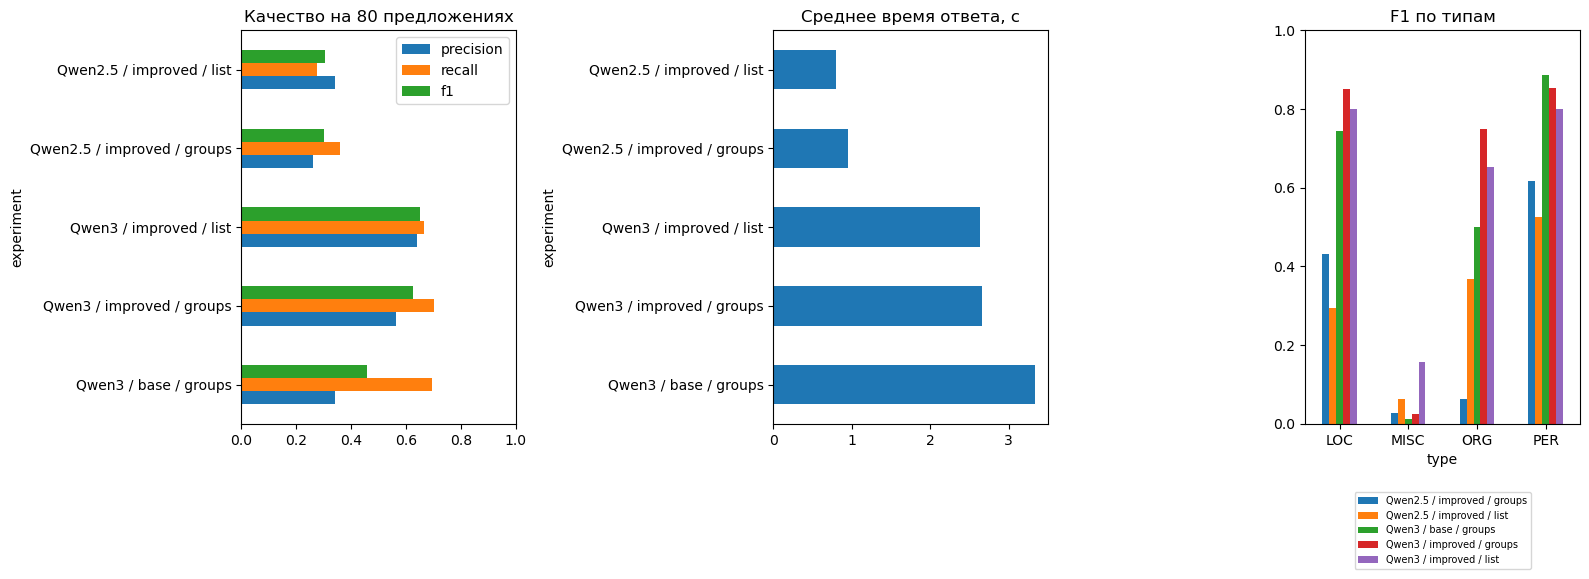

In [12]:
experiments = {
    "Qwen3 / base / groups": (base, False),
    "Qwen3 / improved / groups": (improved_grouped, False),
    "Qwen3 / improved / list": (improved_ordered, True),
    "Qwen2.5 / improved / groups": (small_grouped, False),
    "Qwen2.5 / improved / list": (small_ordered, True),
}
summary = pd.concat([evaluate_records(records, ordered=ordered).assign(experiment=name)
                     for name, (records, ordered) in experiments.items()], ignore_index=True)
by_type = pd.concat([evaluate_records(records, entity_type=kind).assign(experiment=name, type=kind)
                     for name, (records, _) in experiments.items() for kind in ["PER", "LOC", "ORG", "MISC"]], ignore_index=True)
display(summary.query("split == 'evaluation'").set_index("experiment").round(4))
display(summary.query("split == 'development'").set_index("experiment").round(4))
display(by_type.query("split == 'evaluation'")[["experiment", "type", "tp", "fp", "fn", "precision", "recall", "f1"]].round(4))
fig, axes = plt.subplots(1, 3, figsize=(16, 6))
evaluation = summary.query("split == 'evaluation'").set_index("experiment")
evaluation[["precision", "recall", "f1"]].plot.barh(ax=axes[0], xlim=(0, 1), title="Качество на 80 предложениях")
evaluation.mean_seconds.plot.barh(ax=axes[1], title="Среднее время ответа, с")
by_type.query("split == 'evaluation'").pivot(index="type", columns="experiment", values="f1").plot.bar(ax=axes[2], ylim=(0, 1), rot=0, title="F1 по типам")
axes[2].legend(fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.16))
plt.tight_layout()
plt.show()


## 13. Пропуски, ошибки типа и MISC

In [13]:
error_rows = []
for name, (records, ordered) in experiments.items():
    for record in records:
        expected = entity_counts(gold[record["id"]])
        predicted = entity_counts(record["entities"])
        missed, extra = expected - predicted, predicted - expected
        missed_texts, extra_texts = Counter(), Counter()
        for (text, kind), count in missed.items():
            missed_texts[text] += count
        for (text, kind), count in extra.items():
            extra_texts[text] += count
        type_errors = sum((missed_texts & extra_texts).values())
        error_rows.append(dict(experiment=name, id=record["id"], split=record["split"],
            text=input_by_id[record["id"]]["text"], fn=sum(missed.values()), fp=sum(extra.values()),
            type_errors=type_errors, omissions=sum(missed.values()) - type_errors,
            extra_mentions=sum(extra.values()) - type_errors,
            missed=list(missed.elements()), extra=list(extra.elements())))
errors = pd.DataFrame(error_rows)
error_summary = errors.groupby(["experiment", "split"])[["fn", "fp", "type_errors", "omissions", "extra_mentions"]].sum()
display(error_summary.xs("evaluation", level="split"))
examples = (errors.query("split == 'evaluation'").assign(total=lambda frame: frame.fn + frame.fp)
            .sort_values("total", ascending=False).groupby("experiment", sort=False).head(1))
with pd.option_context("display.max_colwidth", 180):
    display(examples[["experiment", "text", "missed", "extra"]])
    misc_ids = {row["id"] for row in inputs if row["split"] == "evaluation" and any(e["type"] == "MISC" for e in gold[row["id"]])}
    display(errors.loc[(errors.experiment == "Qwen3 / improved / list") & errors.id.isin(misc_ids),
                       ["text", "missed", "extra"]].head(4))
print("Группировка:", improved_grouped[0]["raw"])
print("Список:", improved_ordered[0]["raw"])


,fn,fp,type_errors,omissions,extra_mentions
experiment,,,,,
Qwen2.5 / improved / groups,86,135,24,62,111
Qwen2.5 / improved / list,97,71,16,81,55
Qwen3 / base / groups,41,180,16,25,164
Qwen3 / improved / groups,40,73,8,32,65
Qwen3 / improved / list,45,50,10,35,40


,experiment,text,missed,extra
335,Qwen2.5 / improved / groups,"Stuttgart 2 -LPR- Balakow 50th , Bobic 61st -RPR- Werder Bremen 1 -LPR- Votava","[(Stuttgart, ORG), (Balakow, PER), (Bobic, PER), (Werder Bremen, ORG), (Votava, PER)]","[(Germany, LOC), (United Kingdom, LOC), (Stuttgart 2 -LPR- Balakow 50th, ORG), (Bobic 61st -RPR-, ORG), (Werder Bremen 1 -LPR- Votava, ORG)]"
480,Qwen2.5 / improved / list,"Brunswijk turned himself into police after Freddy Pinas , a Surinamese-born visitor from the Netherlands , accused Brunswijk of trying to kill him on Sunday after a bar-room br...","[(Brunswijk, PER), (Freddy Pinas, PER), (Surinamese-born, MISC), (Netherlands, LOC), (Moengo, LOC), (Paramaribo, LOC), (Ro Gajadhar, PER)]","[(Freddy Pinas, MISC), (Surinamese-born visitor from the Netherlands, ORG)]"
91,Qwen3 / base / groups,Bolton 3 2 1 0 5 2 7,"[(Bolton, ORG)]","[(Bolton, MISC), (3, MISC), (2, MISC), (2, MISC), (1, MISC), (0, MISC), (5, MISC), (7, MISC)]"
185,Qwen3 / improved / groups,"The quake struck at 11.16 a.m. -LPR- 1716 GMT -RPR- and was centred 10 miles -LPR- 16 km -RPR- south of the port of Quepos , which is 90 miles -LPR- 140 km -RPR- south of the c...","[(GMT, MISC)]","[(Costa Rican Volcanic and Seismologicial Observatory, LOC), (11.16 a.m., MISC), (1716 GMT, MISC), (10 miles, MISC), (16 km, MISC), (90 miles, MISC), (140 km, MISC)]"
266,Qwen3 / improved / list,The MQM speaks for Urdu-speaking Moslems who migrated from India at Partition in 1947 and their descendants .,"[(Urdu-speaking Moslems, MISC), (Partition, LOC)]","[(Urdu-speaking, MISC), (Moslems, MISC), (Partition, MISC), (1947, MISC)]"


,text,missed,extra
221,"Brazilian Planning Minister Antonio Kandir will submit to a draft copy of the 1997 federal budget to Congress on Thursday , a ministry spokeswoman said .",[],"[(1997, MISC), (federal budget, MISC)]"
226,"Rudolf Gajdos , head of Slovak Interpol , told a news conference Dutroux was also believed to have planned the kidnapping of at least one Slovak woman .","[(Slovak, MISC), (Interpol, ORG)]","[(Slovak Interpol, ORG)]"
232,Nuclear pact will be a step to disarmament-China .,"[(disarmament-China, MISC)]","[(China, LOC)]"
240,"Lebed said on Wednesday he had clinched a truce with Chechen separatists and he promised to halt a threatened bombing assault on Grozny , which the rebels have held since Augus...",[],[]


Группировка: {
  "entities": {
    "PER": [
      "Thierry Dehaan"
    ],
    "LOC": [],
    "ORG": [],
    "MISC": []
  }
}
Список: {
  "entities": [
    {
      "text": "Thierry Dehaan",
      "type": "PER"
    }
  ]
}


## 14. Сохранение результатов

In [14]:
generation_stats = []
for name, (records, _) in experiments.items():
    assert len(records) == 100 and len({r["id"] for r in records}) == 100
    assert Counter(r["split"] for r in records) == {"development": 20, "evaluation": 80}
    generation_stats.append(dict(experiment=name,
        mean_input_tokens=np.mean([r["input_tokens"] for r in records]),
        mean_output_tokens=np.mean([r["output_tokens"] for r in records]),
        truncated=sum(r["done_reason"] == "length" for r in records)))
generation_stats = pd.DataFrame(generation_stats)
summary.to_csv(RESULTS / "comparison.csv", index=False)
by_type.to_csv(RESULTS / "by_type.csv", index=False)
error_summary.to_csv(RESULTS / "error_summary.csv")
errors.to_csv(RESULTS / "errors.csv", index=False)
generation_stats.to_csv(RESULTS / "generation_stats.csv", index=False)
settings = dict(dataset="tner/conll2003", split="train", seed=42, sentences=100,
                development=20, evaluation=80, options=OPTIONS, models=["qwen3:4b-instruct", "qwen2.5:1.5b"])
(RESULTS / "settings.json").write_text(json.dumps(settings, indent=2), encoding="utf-8")
client.generate(model="qwen2.5:1.5b", keep_alive=0)
display(generation_stats.round(2))
print("Сохранено 500 ответов, таблицы и параметры эксперимента")


,experiment,mean_input_tokens,mean_output_tokens,truncated
0,Qwen3 / base / groups,103.29,54.69,0
1,Qwen3 / improved / groups,274.29,44.98,0
2,Qwen3 / improved / list,274.29,46.94,0
3,Qwen2.5 / improved / groups,274.29,36.48,0
4,Qwen2.5 / improved / list,274.29,31.75,0


Сохранено 500 ответов, таблицы и параметры эксперимента
